# 05 · Figures, tables and statistical evidence

Loads `data/processed/`, saves every figure (PNG) and table (CSV) of the paper to `figures/`.
No new strategies or thresholds: this notebook only reads saved results, tests them, and
recomputes the same strategies under the robustness variations listed in PLAN.md 5g.

1. Setup and data
2. Figure 1: the factor and its volatility
3. Figure 2: PCA
4. Figure 3: volatility forecasts
5. Figures 4 and 5: the portfolios
6. Table 1: the direction model (bagging)
7. Table 2: volatility forecast accuracy and Diebold-Mariano tests
8. Table 3: crisis table
9. Table 4: performance of every strategy
10. Table 5: statistical evidence (t-stats, betas, bootstrap, worst quarters)
11. Appendix: robustness table and currency dendrogram
12. Checks

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform

import helpers

os.makedirs(helpers.FIGURES, exist_ok=True)

# One clean style for every chart. Four colours, always in the same order, plus different
# line styles, so the series can be told apart without colour (print, colour blindness).
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
STYLES = ["-", "--", "-.", ":"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.edgecolor": "#888888", "legend.frameon": False, "lines.linewidth": 1.6,
})

def save(fig, name, caption):
    # Caption under the chart, then save as PNG
    fig.text(0.01, -0.02, caption, ha="left", va="top", fontsize=8.5, color="#52514e", wrap=True)
    fig.savefig(f"{helpers.FIGURES}/{name}.png", bbox_inches="tight")
    plt.show()

def save_table(df, name):
    df.to_csv(f"{helpers.FIGURES}/{name}.csv")
    print(df.to_string())

## 1. Data

In [2]:
P = helpers.PROCESSED
weekly = pd.read_csv(f"{P}/weekly.csv", index_col=0, parse_dates=True)
weekly = weekly[weekly.index.year <= helpers.LAST_TEST_YEAR]
overlay = pd.read_csv(f"{P}/overlay.csv", index_col=0, parse_dates=True)
rt = pd.read_csv(f"{P}/risk_targeted.csv", index_col=0, parse_dates=True)
carry = pd.read_csv(f"{P}/carry.csv", index_col=0, parse_dates=True)
fc = pd.read_csv(f"{P}/forecasts.csv", index_col=0, parse_dates=True)
pca = pd.read_csv(f"{P}/pca.csv", index_col=0)
regimes = pd.read_csv(f"{P}/regimes.csv", index_col=0, parse_dates=True)
bag = pd.read_csv(f"{P}/bagging_results.csv")
bag_conf = pd.read_csv(f"{P}/bagging_confusion.csv", index_col=0)
bag_imp = pd.read_csv(f"{P}/bagging_importance.csv", index_col=0).iloc[:, 0]

# All strategy return series in one table (weekly, 2010 to the last test year)
port_names = ["Unhedged", "Hedged", "Unhedged + trend", "Unhedged + model"]
rt_names = ["Buy and hold", "FX warning only", "Equity vol target", "Equity vol target + FX warning"]
returns = pd.concat([
    overlay[port_names],
    rt[[f"rt_{n}" for n in rt_names]].rename(columns=lambda c: c[3:]),
    overlay[["trend", "model"]].rename(columns={"trend": "Trend overlay alone", "model": "Model overlay alone"}),
    carry[["Plain carry", "Vol-managed carry"]],
], axis=1)
# Keep the weeks where every strategy has a result (the regime file has one extra final week)
returns = returns.dropna()
overlay = overlay.loc[returns.index]
sp_chf = overlay["Unhedged"]   # the S&P 500 in CHF, the investor's equity return
print("Strategies:", returns.shape[1], "| weeks:", len(returns),
      "|", returns.index[0].date(), "to", returns.index[-1].date())

Strategies: 12 | weeks: 730 | 2010-01-01 to 2023-12-22


## 2. Figure 1: the factor and its volatility

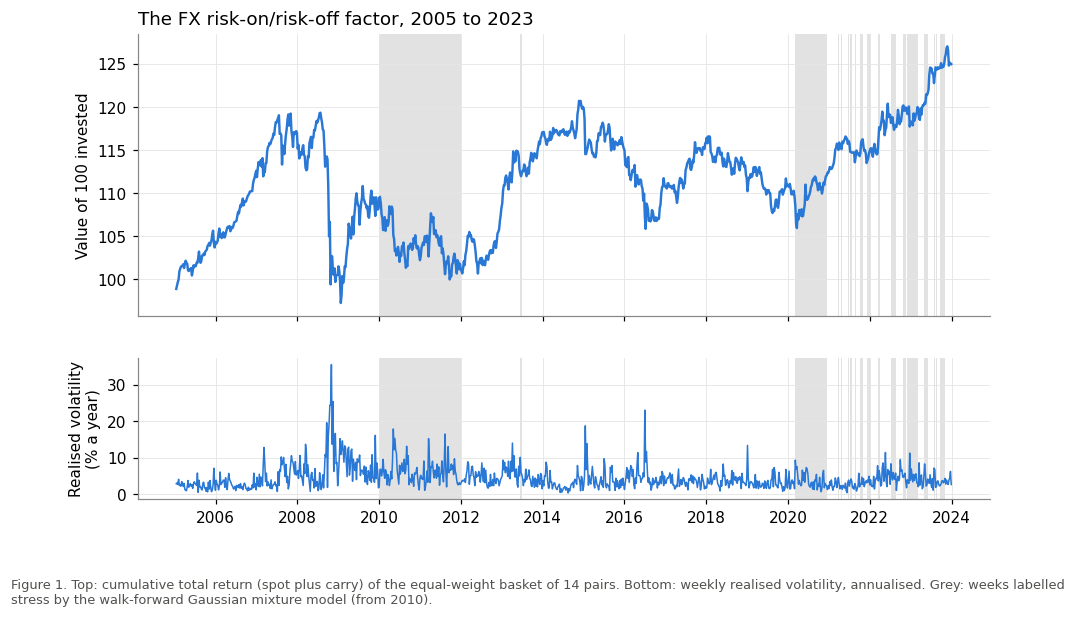

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
growth = 100 * (1 + weekly["factor"]).cumprod()
ax1.plot(growth.index, growth, color=COLORS[0])
ax2.plot(weekly.index, weekly["rv"] * 100, color=COLORS[0], linewidth=1)

# Shade the weeks the regime model labelled as stress (available from 2010)
stress = regimes["stress_gmm"].astype(bool)
for ax in (ax1, ax2):
    blocks = (stress != stress.shift()).cumsum()
    for _, b in stress[stress].groupby(blocks[stress]):
        ax.axvspan(b.index[0], b.index[-1], color="#d0d0d0", alpha=0.6, linewidth=0)

ax1.set_ylabel("Value of 100 invested")
ax1.set_title("The FX risk-on/risk-off factor, 2005 to " + str(helpers.LAST_TEST_YEAR), loc="left")
ax2.set_ylabel("Realised volatility\n(% a year)")
save(fig, "fig1_factor",
     "Figure 1. Top: cumulative total return (spot plus carry) of the equal-weight basket of 14 pairs. "
     "Bottom: weekly realised volatility, annualised. Grey: weeks labelled stress by the "
     "walk-forward Gaussian mixture model (from 2010).")

## 3. Figure 2: PCA

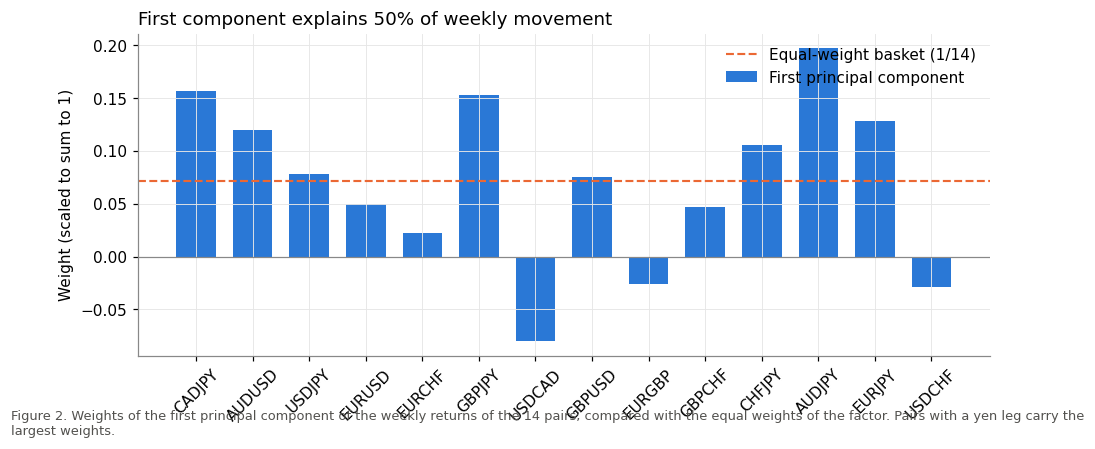

In [4]:
w = pca["pc1_weight"] / pca["pc1_weight"].sum()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(w.index, w, color=COLORS[0], width=0.7, label="First principal component")
ax.axhline(1 / 14, color=COLORS[1], linestyle="--", linewidth=1.4, label="Equal-weight basket (1/14)")
ax.axhline(0, color="#888888", linewidth=0.8)
ax.set_ylabel("Weight (scaled to sum to 1)")
ax.set_title(f"First component explains {pca['variance_share'].iloc[0]:.0%} of weekly movement",
             loc="left")
ax.legend(loc="upper right")
plt.xticks(rotation=45)
save(fig, "fig2_pca",
     "Figure 2. Weights of the first principal component of the weekly returns of the 14 pairs, "
     "compared with the equal weights of the factor. Pairs with a yen leg carry the largest weights.")

## 4. Figure 3: volatility forecasts

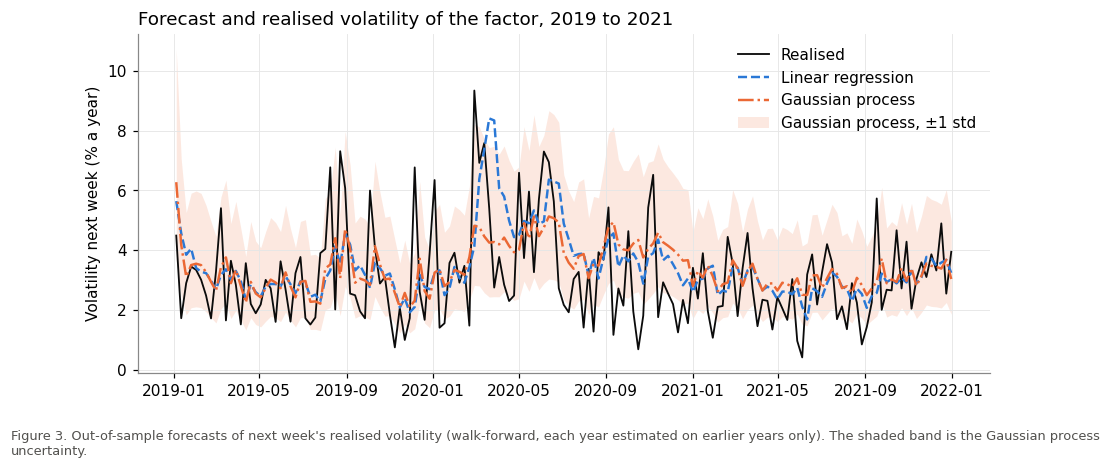

In [5]:
part = fc.loc["2019":"2021"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(part.index, np.exp(part["realised"]) * 100, color="#0b0b0b", linewidth=1.2, label="Realised")
ax.plot(part.index, np.exp(part["regression"]) * 100, color=COLORS[0], linestyle="--", label="Linear regression")
ax.plot(part.index, np.exp(part["gp"]) * 100, color=COLORS[1], linestyle="-.", label="Gaussian process")
ax.fill_between(part.index, np.exp(part["gp"] - part["gp_std"]) * 100,
                np.exp(part["gp"] + part["gp_std"]) * 100, color=COLORS[1], alpha=0.15,
                linewidth=0, label="Gaussian process, ±1 std")
ax.set_ylabel("Volatility next week (% a year)")
ax.set_title("Forecast and realised volatility of the factor, 2019 to 2021", loc="left")
ax.legend(loc="upper right")
save(fig, "fig3_vol_forecast",
     "Figure 3. Out-of-sample forecasts of next week's realised volatility (walk-forward, each "
     "year estimated on earlier years only). The shaded band is the Gaussian process uncertainty.")

## 5. Figures 4 and 5: the portfolios

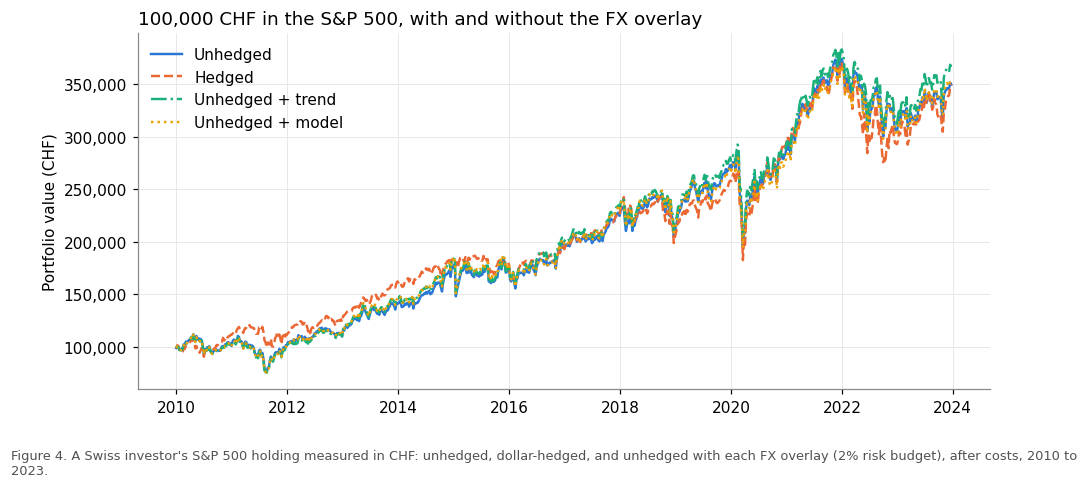

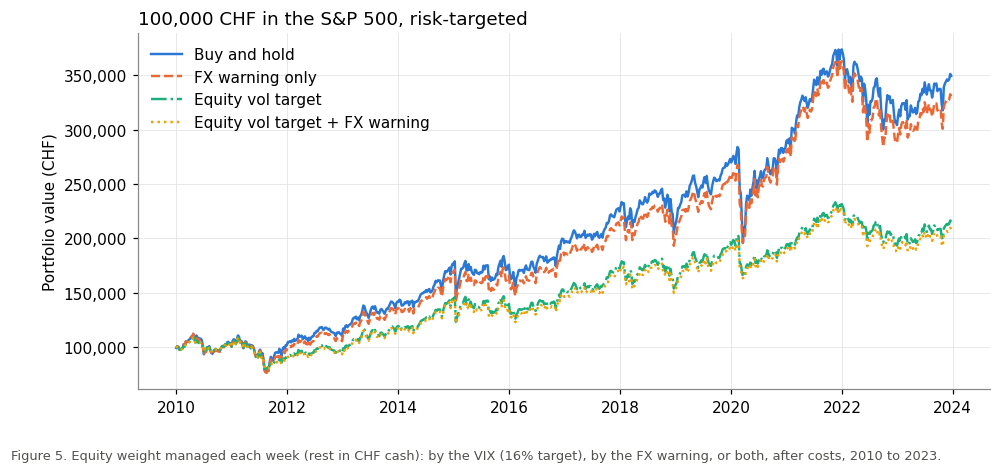

In [6]:
def growth_chart(df, names, title, file, caption):
    fig, ax = plt.subplots(figsize=(10, 4.2))
    for i, n in enumerate(names):
        value = 100_000 * (1 + df[n]).cumprod()
        ax.plot(value.index, value, color=COLORS[i], linestyle=STYLES[i], label=n)
    ax.set_ylabel("Portfolio value (CHF)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_title(title, loc="left")
    ax.legend(loc="upper left")
    save(fig, file, caption)

growth_chart(returns, port_names, "100,000 CHF in the S&P 500, with and without the FX overlay",
             "fig4_portfolios",
             "Figure 4. A Swiss investor's S&P 500 holding measured in CHF: unhedged, dollar-hedged, and "
             "unhedged with each FX overlay (2% risk budget), after costs, 2010 to "
             f"{helpers.LAST_TEST_YEAR}.")
growth_chart(returns, rt_names, "100,000 CHF in the S&P 500, risk-targeted", "fig5_risk_targeting",
             "Figure 5. Equity weight managed each week (rest in CHF cash): by the VIX (16% target), "
             "by the FX warning, or both, after costs, 2010 to " + f"{helpers.LAST_TEST_YEAR}.")

## 6. Table 1: the direction model (bagging)

In [7]:
# Is the test accuracy different from a coin flip? Binomial test on all test weeks.
correct = int(round((bag["test_acc"] * bag["n_test"]).sum()))
n = int(bag["n_test"].sum())
binom = stats.binomtest(correct, n, 0.5)

t1 = bag.set_index("year").round(3)
save_table(t1, "table1_bagging_by_year")
print(f"\nTest accuracy {correct / n:.3f} on {n} weeks; binomial test vs 50%: p = {binom.pvalue:.3f}")
print(f"Average train accuracy {bag['train_acc'].mean():.3f} vs test {bag['test_acc'].mean():.3f}")
print("\nConfusion matrix (rows actual, columns predicted; 1 = up):")
print(bag_conf.to_string())
print("\nWhat the last model relied on (feature importance):")
print(bag_imp.round(3).to_string())

      train_acc  test_acc  n_test
year                             
2010      0.827     0.396      53
2011      0.946     0.519      52
2012      0.920     0.519      52
2013      0.682     0.519      52
2014      0.655     0.481      52
2015      0.644     0.519      52
2016      0.716     0.491      53
2017      0.857     0.481      52
2018      0.845     0.538      52
2019      0.714     0.519      52
2020      0.829     0.423      52
2021      0.618     0.547      53
2022      0.661     0.500      52
2023      0.786     0.569      51

Test accuracy 0.501 on 730 weeks; binomial test vs 50%: p = 0.970
Average train accuracy 0.764 vs test 0.502

Confusion matrix (rows actual, columns predicted; 1 = up):
          0    1
actual          
0       101  253
1       111  265

What the last model relied on (feature importance):
ret_1w           0.190
ret_4w           0.152
vix_change_4w    0.149
ret_52w          0.144
carry            0.140
ret_13w          0.120
vix              0.104


## 7. Table 2: volatility forecast accuracy and Diebold-Mariano tests

In [8]:
def newey_west_mean(series, lags=4):
    # Mean of a series with a Newey-West t-stat (robust to autocorrelation)
    res = sm.OLS(series.values, np.ones(len(series))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return res.params[0], res.tvalues[0], res.pvalues[0]

# Diebold-Mariano: is the model's squared forecast error significantly smaller than naive's?
# Positive difference = the model is better.
err = fc[["naive", "regression", "garch", "gp"]].sub(fc["realised"], axis=0) ** 2
rows = {}
for m in ["regression", "garch", "gp"]:
    _, t, p = newey_west_mean(err["naive"] - err[m])
    rows[m] = {"MSE": err[m].mean(), "R2 vs naive": 1 - err[m].mean() / err["naive"].mean(),
               "DM t-stat vs naive": t, "p-value": p}
rows["naive"] = {"MSE": err["naive"].mean(), "R2 vs naive": 0.0}
_, t, p = newey_west_mean(err["garch"] - err["regression"])
t2 = pd.DataFrame(rows).T.loc[["naive", "regression", "garch", "gp"]].round(3)
save_table(t2, "table2_vol_forecasts")
print(f"\nRegression vs GARCH: DM t-stat {t:.2f}, p = {p:.3f}")

              MSE  R2 vs naive  DM t-stat vs naive  p-value
naive       0.396        0.000                 NaN      NaN
regression  0.263        0.336               8.677    0.000
garch       0.320        0.191               4.931    0.000
gp          0.314        0.207               3.182    0.001

Regression vs GARCH: DM t-stat 5.21, p = 0.000


## 8. Table 3: crisis table

In [9]:
crises = {
    "2011 summer (euro crisis)": ("2011-07-01", "2011-09-30"),
    "2015 SNB shock (January)": ("2015-01-01", "2015-01-31"),
    "2018 Q4 selloff": ("2018-10-01", "2018-12-31"),
    "2020 Covid crash (Feb-Mar)": ("2020-02-15", "2020-03-31"),
    "2022 full year": ("2022-01-01", "2022-12-31"),
}
names = port_names + rt_names[2:]
t3 = pd.DataFrame({c: ((1 + returns.loc[a:b, names]).prod() - 1) * 100_000
                   for c, (a, b) in crises.items()}).T.round(0)
print("Change in value of a 100,000 CHF portfolio, in CHF:")
save_table(t3, "table3_crises")

Change in value of a 100,000 CHF portfolio, in CHF:
                            Unhedged   Hedged  Unhedged + trend  Unhedged + model  Equity vol target  Equity vol target + FX warning
2011 summer (euro crisis)    -4422.0 -10820.0           -3824.0           -4122.0            -6985.0                         -7406.0
2015 SNB shock (January)    -10541.0  -4498.0          -12577.0          -12081.0            -9956.0                         -9972.0
2018 Q4 selloff             -13830.0 -15355.0          -13090.0          -14456.0           -13457.0                        -13457.0
2020 Covid crash (Feb-Mar)  -26135.0 -25034.0          -25389.0          -25828.0           -17455.0                        -16889.0
2022 full year              -18636.0 -20991.0          -18530.0          -17924.0           -16490.0                        -17640.0


## 9. Table 4: performance of every strategy

In [10]:
# Turnover = average yearly sum of position changes (0 for passive portfolios)
positions = {
    "Unhedged + trend": overlay["pos_trend"], "Trend overlay alone": overlay["pos_trend"],
    "Unhedged + model": overlay["pos_model"], "Model overlay alone": overlay["pos_model"],
    "Vol-managed carry": carry["pos_carry"],
}
for n in rt_names:
    positions[n] = rt[f"w_{n}"]
years = len(returns) / 52

t4 = pd.DataFrame({
    "return p.a.": (1 + returns).prod() ** (52 / len(returns)) - 1,
    "volatility": returns.std() * np.sqrt(52),
    "Sharpe": returns.apply(helpers.sharpe_ratio),
    "worst loss": returns.apply(helpers.max_drawdown),
    "turnover p.a.": pd.Series({n: positions[n].diff().abs().sum() / years for n in positions}),
}).loc[returns.columns].round(3)
t4["turnover p.a."] = t4["turnover p.a."].fillna(0)   # passive strategies never trade
save_table(t4, "table4_performance")

                                return p.a.  volatility  Sharpe  worst loss  turnover p.a.
Unhedged                              0.093       0.182   0.582      -0.316          0.000
Hedged                                0.093       0.165   0.625      -0.320          0.000
Unhedged + trend                      0.097       0.182   0.600      -0.324          1.824
Unhedged + model                      0.094       0.185   0.579      -0.321          2.879
Buy and hold                          0.093       0.182   0.582      -0.316          0.000
FX warning only                       0.089       0.178   0.570      -0.320          0.427
Equity vol target                     0.056       0.142   0.456      -0.269          2.723
Equity vol target + FX warning        0.054       0.142   0.442      -0.269          2.903
Trend overlay alone                   0.003       0.019   0.181      -0.036          1.824
Model overlay alone                   0.001       0.015   0.067      -0.063          2.879

## 10. Table 5: statistical evidence

In [11]:
# (a) Each strategy: is its mean return different from zero, and how does it move with
# the investor's equities (beta)? Newey-West standard errors, 4 lags.
rows = {}
for n in returns.columns:
    r = returns[n]
    mean, t, p = newey_west_mean(r)
    beta_fit = sm.OLS(r.values, sm.add_constant(sp_chf.values)).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    rows[n] = {"mean p.a.": mean * 52, "t-stat": t, "p-value": p,
               "beta to S&P (CHF)": beta_fit.params[1], "beta t-stat": beta_fit.tvalues[1]}
    # The S&P against itself has beta 1 by definition: no test to report
    if np.allclose(r.values, sp_chf.values):
        rows[n]["beta t-stat"] = np.nan
t5a = pd.DataFrame(rows).T.round(3)
save_table(t5a, "table5a_returns_and_betas")

                                mean p.a.  t-stat  p-value  beta to S&P (CHF)  beta t-stat
Unhedged                            0.106   2.422    0.015              1.000          NaN
Hedged                              0.103   2.556    0.011              0.758       12.555
Unhedged + trend                    0.109   2.513    0.012              0.996      126.531
Unhedged + model                    0.107   2.405    0.016              1.012      184.230
Buy and hold                        0.106   2.422    0.015              1.000          NaN
FX warning only                     0.101   2.353    0.019              0.969       58.227
Equity vol target                   0.065   1.898    0.058              0.749       21.801
Equity vol target + FX warning      0.063   1.835    0.067              0.738       19.452
Trend overlay alone                 0.003   0.713    0.476             -0.004       -0.533
Model overlay alone                 0.001   0.258    0.797              0.012        2.228

In [12]:
# (b) Is each strategy's Sharpe ratio better than its benchmark's by more than luck?
# Block bootstrap: resample 13-week blocks (keeping the time structure) 5,000 times,
# the same weeks for both series. p-value = share of draws where the difference is <= 0.
def block_bootstrap_sharpe_diff(a, b, block=13, draws=5000, seed=helpers.SEED):
    rng = np.random.default_rng(seed)
    a, b = a.values, b.values
    n = len(a)
    diffs = np.empty(draws)
    for i in range(draws):
        starts = rng.integers(0, n - block, size=n // block + 1)
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
        sa = a[idx].mean() / a[idx].std() * np.sqrt(52)
        sb = b[idx].mean() / b[idx].std() * np.sqrt(52)
        diffs[i] = sa - sb
    return diffs

pairs = [
    ("Unhedged + trend", "Unhedged"),
    ("Unhedged + model", "Unhedged"),
    ("Equity vol target", "Buy and hold"),
    ("Equity vol target + FX warning", "Equity vol target"),
    ("Vol-managed carry", "Plain carry"),
]
rows = {}
for s, b in pairs:
    d = block_bootstrap_sharpe_diff(returns[s], returns[b])
    rows[f"{s} vs {b}"] = {
        "Sharpe difference": helpers.sharpe_ratio(returns[s]) - helpers.sharpe_ratio(returns[b]),
        "95% interval low": np.percentile(d, 2.5), "95% interval high": np.percentile(d, 97.5),
        "p-value (one-sided)": (d <= 0).mean()}
t5b = pd.DataFrame(rows).T.round(3)
save_table(t5b, "table5b_sharpe_bootstrap")

                                                     Sharpe difference  95% interval low  95% interval high  p-value (one-sided)
Unhedged + trend vs Unhedged                                     0.018            -0.029              0.074                0.193
Unhedged + model vs Unhedged                                    -0.003            -0.039              0.041                0.509
Equity vol target vs Buy and hold                               -0.126            -0.241             -0.017                0.985
Equity vol target + FX warning vs Equity vol target             -0.014            -0.038              0.007                0.908
Vol-managed carry vs Plain carry                                -0.098            -0.199              0.043                0.906


In [13]:
# (c) In the worst 16% of quarters for the benchmark, did the strategy lose less?
# Paired difference per quarter, with a t-test. Caveat: few quarters, so low power.
quarterly = (1 + returns).resample("QE").prod() - 1
rows = {}
for s, b in pairs[:4]:
    worst = quarterly[b] <= quarterly[b].quantile(0.16)
    diff = (quarterly.loc[worst, s] - quarterly.loc[worst, b]) * 100_000
    t, p = stats.ttest_1samp(diff, 0)
    rows[f"{s} vs {b}"] = {"quarters": int(worst.sum()), "avg CHF saved per quarter": diff.mean(),
                           "t-stat": t, "p-value": p}
t5c = pd.DataFrame(rows).T.round(3)
save_table(t5c, "table5c_worst_quarters")
print("\nNote: several strategies were tested; single p-values below 0.05 should be read with care.")

                                                     quarters  avg CHF saved per quarter  t-stat  p-value
Unhedged + trend vs Unhedged                              9.0                    361.955   1.303    0.229
Unhedged + model vs Unhedged                              9.0                    -12.201  -0.051    0.961
Equity vol target vs Buy and hold                         9.0                   1568.328   1.506    0.170
Equity vol target + FX warning vs Equity vol target       9.0                   -123.289  -0.739    0.481

Note: several strategies were tested; single p-values below 0.05 should be read with care.


## 11. Appendix: robustness and currency dendrogram

In [14]:
# Sharpe ratio of the main strategies under each variation (PLAN.md 5g).
base = {
    "Unhedged + trend": returns["Unhedged + trend"],
    "Unhedged + model": returns["Unhedged + model"],
    "Equity vol target + FX warning": returns["Equity vol target + FX warning"],
    "Vol-managed carry": returns["Vol-managed carry"],
}
pos_for = {"Unhedged + trend": (overlay["pos_trend"], helpers.COST_BP),
           "Unhedged + model": (overlay["pos_model"], helpers.COST_BP),
           "Equity vol target + FX warning": (rt["w_Equity vol target + FX warning"], 5),
           "Vol-managed carry": (carry["pos_carry"], helpers.COST_BP)}

robust = {"Base case": {k: helpers.sharpe_ratio(v) for k, v in base.items()}}

# Costs doubled: subtract the same cost a second time
robust["Costs doubled"] = {k: helpers.sharpe_ratio(v - pos_for[k][1] / 1e4 * pos_for[k][0].diff().abs().fillna(0))
                           for k, v in base.items()}

# 2022 left out
robust["Without 2022"] = {k: helpers.sharpe_ratio(v[v.index.year != 2022]) for k, v in base.items()}

# Model overlay: flat in stress weeks instead of following the trend
factor = weekly["factor"].loc[overlay.index]
pos_flat = overlay["pos_model"].where(~overlay["stress"].astype(bool), 0.0)
ov_flat = (pos_flat.shift(1) * factor - helpers.COST_BP / 1e4 * pos_flat.diff().abs().fillna(0)).fillna(0)
robust["Flat in stress (model)"] = {"Unhedged + model": helpers.sharpe_ratio(returns["Unhedged"] + ov_flat)}

# Price-error rule switched off: rebuild the factor from the raw closes without that rule,
# then recompute the trend overlay exactly as before
def load_close(name):
    df = pd.read_csv(f"{helpers.RAW}/{name}.csv", header=[0, 1], index_col=0, parse_dates=True)
    return df["Close"].iloc[:, 0]

with open(f"{helpers.RAW}/download_date.txt") as f:
    download_date = pd.Timestamp(f.read().strip())
closes = pd.DataFrame({p: load_close(p) for p in helpers.ALL_PAIRS})
closes = closes[closes.index < download_date]
missing = closes["AUDUSD"].isna()
closes.loc[missing, "AUDUSD"] = (closes["AUDJPY"] / closes["USDJPY"])[missing]
closes = closes.reindex(pd.bdate_range(closes.index.min(), closes.index.max())).ffill().dropna()
raw_factor = (closes.resample("W-FRI").last().pct_change().mean(axis=1)
              + weekly["carry"] / 100 / 52).reindex(weekly.index)
trend_raw = np.sign((1 + raw_factor).rolling(52).apply(np.prod, raw=True) - 1) * 0.40
trend_raw = trend_raw.loc[overlay.index]
ov_raw = (trend_raw.shift(1) * raw_factor.loc[overlay.index]
          - helpers.COST_BP / 1e4 * trend_raw.diff().abs().fillna(0)).fillna(0)
robust["Price-error rule off (trend)"] = {"Unhedged + trend": helpers.sharpe_ratio(returns["Unhedged"] + ov_raw)}

t6 = pd.DataFrame(robust).T[list(base)].round(3)
print("Sharpe ratio under each variation (blank = not applicable):")
save_table(t6, "tableA1_robustness")

Sharpe ratio under each variation (blank = not applicable):
                              Unhedged + trend  Unhedged + model  Equity vol target + FX warning  Vol-managed carry
Base case                                0.600             0.579                           0.442              0.142
Costs doubled                            0.597             0.574                           0.431              0.107
Without 2022                             0.734             0.705                           0.573              0.119
Flat in stress (model)                     NaN             0.575                             NaN                NaN
Price-error rule off (trend)             0.600               NaN                             NaN                NaN


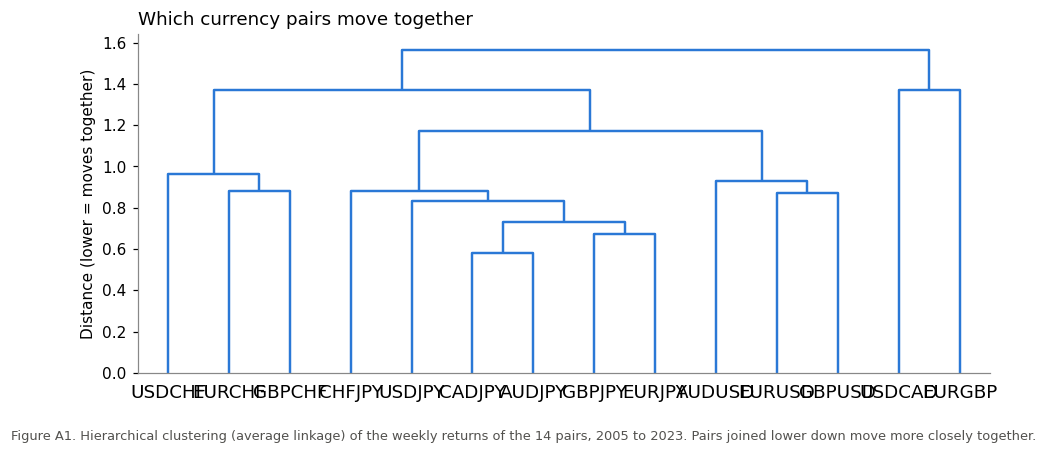

In [15]:
# Which currency pairs move together? Distance = sqrt(2 x (1 - correlation)).
corr = weekly[[f"ret_{p}" for p in helpers.ALL_PAIRS]].corr()
corr.index = corr.columns = helpers.ALL_PAIRS
dist = np.sqrt(2 * (1 - corr.clip(-1, 1)))
link = linkage(squareform(dist.values, checks=False), method="average")

fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(link, labels=corr.index.tolist(), ax=ax, color_threshold=0,
           above_threshold_color=COLORS[0])
ax.set_ylabel("Distance (lower = moves together)")
ax.set_title("Which currency pairs move together", loc="left")
ax.grid(False)
save(fig, "figA1_dendrogram",
     "Figure A1. Hierarchical clustering (average linkage) of the weekly returns of the 14 pairs, "
     "2005 to " + f"{helpers.LAST_TEST_YEAR}. Pairs joined lower down move more closely together.")

## 12. Checks

In [16]:
expected = ["fig1_factor", "fig2_pca", "fig3_vol_forecast", "fig4_portfolios", "fig5_risk_targeting",
            "figA1_dendrogram"]
for f in expected:
    assert os.path.exists(f"{helpers.FIGURES}/{f}.png"), f"Missing figure {f}"
for t in ["table1_bagging_by_year", "table2_vol_forecasts", "table3_crises", "table4_performance",
          "table5a_returns_and_betas", "table5b_sharpe_bootstrap", "table5c_worst_quarters",
          "tableA1_robustness"]:
    assert os.path.exists(f"{helpers.FIGURES}/{t}.csv"), f"Missing table {t}"

# No holdout data in any result
assert returns.index.max().year <= helpers.LAST_TEST_YEAR, "Holdout data used"
# The base-case Sharpe in the robustness table matches the performance table
assert abs(t6.loc["Base case", "Unhedged + trend"] - t4.loc["Unhedged + trend", "Sharpe"]) < 0.002

print("All checks passed")

All checks passed
